# Modelo XGBoost — importancia de features del modelo congelado

Este notebook solo lee. Carga el modelo congelado de `models/xgboost/` con `load_xgboost_model()` y calcula la importancia de cada feature por **gain**. No reentrena, no usa datos de train, val ni test y no toca las probabilidades de test.

**Árboles que se cuentan.** El early stopping sigue entrenando 50 rondas después de la mejor, así que el booster guardado tiene más árboles de los que usa la predicción: `predict_proba` usa solo los primeros `best_iteration + 1`. La importancia se calcula sobre esos árboles (`booster[: best_iteration + 1]`), que son los que deciden las predicciones del modelo.

**Qué mide cada tipo de importancia:**

- `gain`: mejora promedio de la función de pérdida en los splits que usan la feature. Es el criterio del ranking.
- `weight`: cantidad de splits que usan la feature.
- `cover`: cantidad promedio de muestras (ponderadas por el hessiano) que pasan por esos splits.
- `total_gain` = `gain` × `weight`.

La proporción del gain es `gain / suma de gain` de las 55 features, la misma normalización que `feature_importances_` de XGBoost. Las features que el modelo nunca usó no aparecen en `get_score` y se completan con 0.

Salidas:

- `reports/xgboost/importancia_gain.csv`, con la tabla completa;
- `reports/xgboost/figuras/importancia_gain.png`, con el top 15.

`*.csv` está en `.gitignore`; para versionar la tabla hace falta `git add -f`.

In [1]:
import sys
from pathlib import Path

# Raíz del repo = primera carpeta hacia arriba que contenga src/.
RAIZ_REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(RAIZ_REPO) not in sys.path:
    sys.path.append(str(RAIZ_REPO))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb

from src.models.xgboost.model import MODEL_DIR, UMBRAL_FINAL, load_xgboost_model

REPORTES_XGB_DIR = RAIZ_REPO / "reports" / "xgboost"
RUTA_TABLA = REPORTES_XGB_DIR / "importancia_gain.csv"
RUTA_FIGURA = REPORTES_XGB_DIR / "figuras" / "importancia_gain.png"

modelo, metadatos = load_xgboost_model()
assert metadatos["umbral"] == UMBRAL_FINAL == 0.87, "El umbral guardado no es el congelado (0.87)"
assert metadatos["best_iteration"] == modelo.best_iteration == 68, "best_iteration no es el del modelo congelado (68)"

booster = modelo.get_booster()
N_ARBOLES_PREDICCION = modelo.best_iteration + 1
booster_usado = booster[:N_ARBOLES_PREDICCION]
assert booster_usado.num_boosted_rounds() == 69
assert len(booster.feature_names) == 55, f"Se esperaban 55 features, el booster tiene {len(booster.feature_names)}"

print(f"Python: {sys.executable} | xgboost {xgb.__version__}")
print(f"Modelo: {MODEL_DIR.relative_to(RAIZ_REPO)} | umbral {metadatos['umbral']} | best_iteration {metadatos['best_iteration']} | "
      f"scale_pos_weight {metadatos['scale_pos_weight']:.4f}")
print(f"Árboles en el booster: {booster.num_boosted_rounds()} | árboles que usa la predicción: {booster_usado.num_boosted_rounds()}")

Python: C:\Users\Andy Ortega\Progras\Proyecto de Graduación\low-and-slow-ids\venv\Scripts\python.exe | xgboost 3.3.0
Modelo: models\xgboost | umbral 0.87 | best_iteration 68 | scale_pos_weight 36.7313
Árboles en el booster: 119 | árboles que usa la predicción: 69


## Ranking completo de las 55 features por gain

In [2]:
importancia = pd.DataFrame({"feature": booster.feature_names})
for tipo in ["gain", "weight", "cover", "total_gain"]:
    importancia[tipo] = importancia["feature"].map(booster_usado.get_score(importance_type=tipo)).fillna(0.0)
importancia["prop_gain"] = importancia["gain"] / importancia["gain"].sum()
importancia = importancia.sort_values(["gain", "feature"], ascending=[False, True], ignore_index=True)
importancia["prop_gain_acumulada"] = importancia["prop_gain"].cumsum()
importancia["usada"] = importancia["weight"] > 0
importancia.insert(0, "posicion", importancia.index + 1)

with pd.option_context("display.max_rows", 100, "display.width", 250):
    print(importancia.to_string(index=False, formatters={
        "gain": "{:.4f}".format, "weight": "{:.0f}".format, "cover": "{:.4f}".format,
        "total_gain": "{:.4f}".format, "prop_gain": "{:.4f}".format, "prop_gain_acumulada": "{:.4f}".format,
    }))

 posicion                     feature       gain weight      cover  total_gain prop_gain prop_gain_acumulada  usada
        1      Bwd Packet Length Mean 46112.4531     19 42313.2812 876136.6250    0.5631              0.5631   True
        2               Fwd IAT Total 11899.4277     23 13440.0439 273686.8438    0.1453              0.7084   True
        3 Total Length of Fwd Packets  4638.0112     17 13443.8467  78846.1875    0.0566              0.7650   True
        4                Fwd IAT Mean  4325.7598     16  8763.2695  69212.1562    0.0528              0.8179   True
        5       Fwd Packet Length Min  3777.1948     30 13016.8750 113315.8438    0.0461              0.8640   True
        6        min_seg_size_forward  2777.8760     24 14137.9131  66669.0234    0.0339              0.8979   True
        7              PSH Flag Count   835.7065      1  3630.6687    835.7065    0.0102              0.9081   True
        8                    Idle Max   793.2832      1  3820.8901    79

## Concentración del gain y features no usadas

Proporción acumulada del gain en las primeras 1, 3, 5 y 10 features del ranking. Se verifica además que los valores coinciden con el diagnóstico interno hecho antes sobre el mismo modelo: `Bwd Packet Length Mean` 0.5631, top 3 0.7650, top 5 0.8640 y 49 de 55 features usadas, todo redondeado a 4 decimales.

In [3]:
acumulada = pd.DataFrame({
    "proporción acumulada del gain": [importancia["prop_gain"].head(k).sum() for k in (1, 3, 5, 10)],
}, index=[f"top {k}" for k in (1, 3, 5, 10)])
print(acumulada.to_string(float_format="{:.4f}".format))

no_usadas = importancia.loc[~importancia["usada"], "feature"].tolist()
print()
print(f"Features usadas en al menos un split: {int(importancia['usada'].sum())} de {len(importancia)}")
print(f"Nunca usadas ({len(no_usadas)}): {', '.join(no_usadas) if no_usadas else 'ninguna'}")

# Verificación contra el diagnóstico interno (valores redondeados a 4 decimales)
assert importancia.loc[0, "feature"] == "Bwd Packet Length Mean"
assert round(importancia.loc[0, "prop_gain"], 4) == 0.5631
assert round(acumulada.loc["top 3"].iloc[0], 4) == 0.7650
assert round(acumulada.loc["top 5"].iloc[0], 4) == 0.8640
assert int(importancia["usada"].sum()) == 49
print()
print("Coincide con el diagnóstico interno: Bwd Packet Length Mean 0.5631 | top 3 0.7650 | top 5 0.8640 | 49 de 55 usadas.")

        proporción acumulada del gain
top 1                          0.5631
top 3                          0.7650
top 5                          0.8640
top 10                         0.9340

Features usadas en al menos un split: 49 de 55
Nunca usadas (6): ACK Flag Count, Bwd Packet Length Max, Bwd Packet Length Min, ECE Flag Count, FIN Flag Count, RST Flag Count

Coincide con el diagnóstico interno: Bwd Packet Length Mean 0.5631 | top 3 0.7650 | top 5 0.8640 | 49 de 55 usadas.


## Gráfico: top 15 por proporción del gain

Barras horizontales ordenadas de mayor a menor, con la proporción del gain escrita al final de cada barra. Se guarda en `reports/xgboost/figuras/importancia_gain.png` a 200 dpi.

Figura guardada en reports\xgboost\figuras\importancia_gain.png


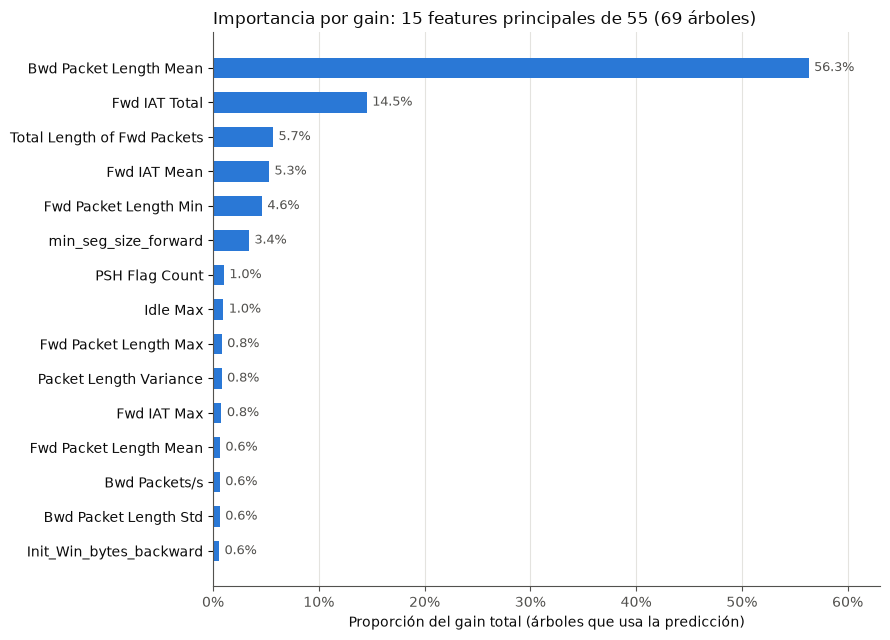

In [4]:
AZUL = "#2a78d6"  # paleta categórica: serie 1
TINTA, TINTA_SUAVE, GRILLA = "#0b0b0b", "#52514e", "#e4e3df"

top15 = importancia.head(15).iloc[::-1]  # la más importante arriba
fig, ax = plt.subplots(figsize=(9, 6.5))
barras = ax.barh(top15["feature"], top15["prop_gain"], height=0.6, color=AZUL)
for barra, valor in zip(barras, top15["prop_gain"]):
    ax.annotate(f"{valor:.1%}", xy=(barra.get_width(), barra.get_y() + barra.get_height() / 2),
                xytext=(4, 0), textcoords="offset points", va="center", color=TINTA_SUAVE, fontsize=9)

ax.set_xlim(0, top15["prop_gain"].max() * 1.12)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_xlabel("Proporción del gain total (árboles que usa la predicción)", color=TINTA)
ax.set_title(f"Importancia por gain: 15 features principales de 55 ({N_ARBOLES_PREDICCION} árboles)",
             color=TINTA, loc="left")
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
for lado in ("left", "bottom"):
    ax.spines[lado].set_color(TINTA_SUAVE)
ax.tick_params(colors=TINTA_SUAVE)
ax.tick_params(axis="y", colors=TINTA)
ax.grid(axis="x", color=GRILLA, linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()

RUTA_FIGURA.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(RUTA_FIGURA, dpi=200)
print(f"Figura guardada en {RUTA_FIGURA.relative_to(RAIZ_REPO)}")
plt.show()

## Tabla completa

Se guarda la tabla de las 55 features con todas las columnas de arriba y se verifica que releída da lo mismo.

In [5]:
importancia.to_csv(RUTA_TABLA, index=False)
releida = pd.read_csv(RUTA_TABLA)
pd.testing.assert_frame_equal(releida, importancia, check_dtype=False)
print(f"Tabla guardada en {RUTA_TABLA.relative_to(RAIZ_REPO)}: {releida.shape[0]} features x {releida.shape[1]} columnas")

Tabla guardada en reports\xgboost\importancia_gain.csv: 55 features x 9 columnas

## Resumen

In [6]:
print("=" * 64)
print("RESUMEN — importancia por gain del modelo XGBoost congelado")
print("=" * 64)
print(f"Árboles contados: {N_ARBOLES_PREDICCION} (los que usa la predicción) de {booster.num_boosted_rounds()} en el booster")
for k in (1, 3, 5, 10):
    print(f"Top {k:<2} acumula {acumulada.loc[f'top {k}'].iloc[0]:.4f} del gain")
print("Top 5: " + ", ".join(f"{f} ({p:.4f})" for f, p in importancia.head(5)[["feature", "prop_gain"]].itertuples(index=False)))
print(f"Usadas: {int(importancia['usada'].sum())} de 55 | nunca usadas: {', '.join(no_usadas)}")
print(f"Archivos: {RUTA_TABLA.relative_to(RAIZ_REPO)} | {RUTA_FIGURA.relative_to(RAIZ_REPO)}")

RESUMEN — importancia por gain del modelo XGBoost congelado
Árboles contados: 69 (los que usa la predicción) de 119 en el booster
Top 1  acumula 0.5631 del gain
Top 3  acumula 0.7650 del gain
Top 5  acumula 0.8640 del gain
Top 10 acumula 0.9340 del gain
Top 5: Bwd Packet Length Mean (0.5631), Fwd IAT Total (0.1453), Total Length of Fwd Packets (0.0566), Fwd IAT Mean (0.0528), Fwd Packet Length Min (0.0461)
Usadas: 49 de 55 | nunca usadas: ACK Flag Count, Bwd Packet Length Max, Bwd Packet Length Min, ECE Flag Count, FIN Flag Count, RST Flag Count
Archivos: reports\xgboost\importancia_gain.csv | reports\xgboost\figuras\importancia_gain.png
